#Aprendizado de maquina Supervisionado

* Modelos de Regressão: Predição de valores numéricos
* Modelos de Classificação: predição de valores categóricos

Demonstra o uso de Pipelines para replicar os modelos mais comuns:
- Regressão Linear e Regularizados
- Regressão Logística
- k-Nearest Neighbors (Classificação e Regressão)
- Support Vector Machines (Classificação e Regressão)


In [ ]:
# Carregar pacotes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Importações do Scikit-learn

# Pré-processamento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Modelos
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR # SVC = Classification, SVR = Regression

# Métricas
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

# Importação do Statsmodels
import statsmodels.api as sm

# Configurações
# Define um estilo visual agradável para os plots
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 6)




In [ ]:
# =============================================================================
# FUNÇÃO AUXILIAR PARA PLOTAR REGIÕES DE DECISÃO
# =============================================================================
def plot_decision_regions(X, y, classifier_pipe, title, resolution=0.1, le=None):

    # Nomes das colunas
    col1, col2 = X.columns[0], X.columns[1]

    # Mapeamento de cores
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')

    # Precisamos dos dados originais para definir os limites do plot
    X_plot = X.values

    # Criar a grade (meshgrid)
    x1_min, x1_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
    x2_min, x2_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))

    # Criar um DataFrame com os pontos da grade
    grid_data = pd.DataFrame(np.array([xx1.ravel(), xx2.ravel()]).T, columns=X.columns)

    # Prever as classes para cada ponto da grade usando o pipeline
    Z = classifier_pipe.predict(grid_data)

    # Se a saída for categórica (ex: '4', '6', '8'), precisamos de um LabelEncoder
    if le is None:
        le = LabelEncoder().fit(y)

    Z_numeric = le.transform(Z).reshape(xx1.shape)

    # Mapeamento de cores
    cmap_light = ListedColormap(['#AAAAFF','#FFAAAA','#AAFFAA']) # Cores para as regiões
    if len(le.classes_) == 2:
         cmap_light = ListedColormap(['#AAAAFF','#FFAAAA'])
    elif len(le.classes_) > 3:
         cmap_light = ListedColormap(plt.cm.Pastel1.colors)


    # Plotar as regiões
    plt.figure(figsize=(10, 6))
    plt.contourf(xx1, xx2, Z_numeric, alpha=0.3, cmap=cmap_light)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # Plotar os pontos de dados
    sns.scatterplot(x=X[col1], y=X[col2], hue=y,
                    palette=sns.color_palette("deep", n_colors=len(le.classes_)),
                    alpha=1.0, edgecolor="black", s=80)

    plt.title(title)
    plt.xlabel(col1)
    plt.ylabel(col2)
    plt.legend(title=y.name)
    plt.show()


# =============================================================================
# FUNÇÃO AUXILIAR PARA CRIAR DADOS "ESPIRAIS"
# =============================================================================
def make_spirals(n_points=100, noise=0.1, n_turns=1):

    n = n_points // 2
    X = np.zeros((n_points, 2))
    y = np.zeros(n_points, dtype=int)

    # Espiral 1 (Classe 0)
    # np.linspace(0.1, 1, n) -> Raio (distância do centro)
    # np.linspace(0, ..., n) -> Ângulo
    r_1 = np.linspace(0.1, 1, n)
    t_1 = np.linspace(0, n_turns * 2 * np.pi, n) + np.random.randn(n) * noise
    X[:n] = np.c_[r_1 * np.sin(t_1), r_1 * np.cos(t_1)]
    y[:n] = 0

    # Espiral 2 (Classe 1) - defasada em pi (180 graus)
    r_2 = np.linspace(0.1, 1, n)
    t_2 = np.linspace(0, n_turns * 2 * np.pi, n) + np.pi + np.random.randn(n) * noise
    X[n:] = np.c_[r_2 * np.sin(t_2), r_2 * np.cos(t_2)]
    y[n:] = 1

    df = pd.DataFrame(X, columns=['X1', 'X2'])
    df['y'] = y.astype('int')
    return df

##Regressão Linear.

Ja vimos como operamos um modelo de regressão linear, foi muito util para encontrar relações na AED.

Porem existem situações que esse modelo pode apresentar instabilidades.
Para isso podemos utilizar regularizadores, para ajudar os coeficientes do modelo a se manterem pequenos. isso é util em casos de muita features, ou uma relação de mais features de observações, para isso podemos usar a regularização L1(Lasso), que possibilita  reduzir os coeficientes exatamente a zero, removendo características por completo. Ou problemas de Multicolinearidades, que podem fazer coeficientes ficarem muito grande, para isso aplica se o Regularizador L2(Ridge). Podemos aplicar ambos por meio do Elasticnet

In [ ]:

# REGRESSÃO LINEAR
# Objetivo: Prever 'disp' (cilindradas-numerico) usando 'cyl' (numero de cilindros-categórico) e 'wt' (numérico-peso)

# Carregar os dados
mtcars = pd.read_csv("https://gist.githubusercontent.com/seankross/a412dfbd88b3db70b74b/raw/5f23f993cd87c283ce766e7ac6b329ee7cc2e1d1/mtcars.csv")
mtcars['wt'] = mtcars['wt'] * 453.592 # para kilos
mtcars['disp'] = mtcars['disp'] * 0.0163871 # para litros


# Seleção de variaveis
y_lm = mtcars['disp']
X_lm = mtcars[['cyl', 'wt']]

# Divisão de dados
X_lm_train, X_lm_test, y_lm_train, y_lm_test = train_test_split(
    X_lm, y_lm, test_size=0.20, stratify=mtcars['cyl'], random_state=2024
)

# (pré-processamento)

# IMPORTANTE: Para Regressão regularizada (L1/L2) é FUNDAMENTAL
# usar StandardScaler.
preprocessor_lm = ColumnTransformer(
    transformers=[
        # ('nome', transformador, colunas)
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['cyl']),
        ('num', StandardScaler(), ['wt'])
    ],
    remainder='drop' # Ignora outras colunas se houver
)

# Defini os modelos
lm_model = LinearRegression() # OLS (Sem regularização)
ridge_model = Ridge(alpha=1.0) # L2 (alpha é a força da penalidade)
lasso_model = Lasso(alpha=.10) # L1 (alpha é a força da penalidade)
elastic_net_model = ElasticNet(alpha=1.0, l1_ratio=0.5) # L1+L2 (ratio=0.5 é 50% L1, 50% L2)

# Cria e Treina o "workflow" (Pipeline) para OLS
lm_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_lm),
    ('model', lm_model)
])
lm_fit = lm_wflow.fit(X_lm_train, y_lm_train)

# Cria e Treina o "workflow" (Pipeline) para Ridge (L2)
ridge_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_lm), # Reusa o mesmo preprocessor
    ('model', ridge_model)
])
ridge_fit = ridge_wflow.fit(X_lm_train, y_lm_train)

#Cria e Treina o "workflow" (Pipeline) para Lasso (L1)
print("\nTreinando Lasso (L1) com alpha=1.0...")
# O pipeline 'lasso_wflow' ainda não foi treinado, ele é o estimador
lasso_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_lm),
    ('model', lasso_model)
])
# Treina o modelo
lasso_fit = lasso_wflow.fit(X_lm_train, y_lm_train)


# Cria e Treina o "workflow" (Pipeline) para ElasticNet
print("Treinando ElasticNet com alpha=1.0, l1_ratio=0.5...")
elastic_net_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_lm),
    ('model', elastic_net_model)
])

# Treina o modelo
elastic_net_fit = elastic_net_wflow.fit(X_lm_train, y_lm_train)


# Avaliar Coeficientes (Comparação)
print("\n## Regressão Linear - Comparação de Coeficientes ##")

# Obter nomes das features
feature_names = lm_fit.named_steps['preprocessor'].get_feature_names_out()

# Extrair coeficientes dos modelos
coefs_ols = lm_fit.named_steps['model'].coef_
coefs_ridge = ridge_fit.named_steps['model'].coef_
coefs_lasso = lasso_fit.named_steps['model'].coef_
coefs_elastic = elastic_net_fit.named_steps['model'].coef_

# Extrair Interceptos
intercept_ols = lm_fit.named_steps['model'].intercept_
intercept_ridge = ridge_fit.named_steps['model'].intercept_
intercept_lasso = lasso_fit.named_steps['model'].intercept_
intercept_elastic = elastic_net_fit.named_steps['model'].intercept_

# Cria tabela comparativa
coef_table = pd.DataFrame({
    'Feature': np.append(feature_names, 'Intercept'),
    'OLS (Linear)': np.append(coefs_ols, intercept_ols),
    'Ridge (L2, a=1.0)': np.append(coefs_ridge, intercept_ridge),
    f'Lasso (L1, a=1.0)': np.append(coefs_lasso, intercept_lasso),
    f'ElasticNet (a=1.0, r=0.5)': np.append(coefs_elastic, intercept_elastic)
}).set_index('Feature')

# Imprimi com formatação
print(coef_table.to_string(float_format="%.4f"))
print("\nNota: Coeficientes Lasso (L1) podem ser zerados (seleção de features).")
print("-" * 40)


#Métricas (Comparação Treino vs. Teste para Overfitting)
print("\n## Regressão Linear - Métricas (Treino vs. Teste) ##")

# Predições no TREINO(comparar os resultados)
y_lm_pred_train = lm_fit.predict(X_lm_train)
y_ridge_pred_train = ridge_fit.predict(X_lm_train)
y_lasso_pred_train = lasso_fit.predict(X_lm_train)
y_elastic_pred_train = elastic_net_fit.predict(X_lm_train)

# Predições no TESTE
y_lm_pred_test = lm_fit.predict(X_lm_test)
y_ridge_pred_test = ridge_fit.predict(X_lm_test)
y_lasso_pred_test = lasso_fit.predict(X_lm_test)
y_elastic_pred_test = elastic_net_fit.predict(X_lm_test)

#  Organizar métricas em um dicionário
metrics_data = {
    # (Modelo, Dataset): {Metricas}
    ('OLS (Linear)', 'Treino'): {
        'RMSE': np.sqrt(mean_squared_error(y_lm_train, y_lm_pred_train)),
        'R²': r2_score(y_lm_train, y_lm_pred_train)
    },
    ('OLS (Linear)', 'Teste'): {
        'RMSE': np.sqrt(mean_squared_error(y_lm_test, y_lm_pred_test)),
        'R²': r2_score(y_lm_test, y_lm_pred_test)
    },

    ('Ridge (L2)', 'Treino'): {
        'RMSE': np.sqrt(mean_squared_error(y_lm_train, y_ridge_pred_train)),
        'R²': r2_score(y_lm_train, y_ridge_pred_train)
    },
    ('Ridge (L2)', 'Teste'): {
        'RMSE': np.sqrt(mean_squared_error(y_lm_test, y_ridge_pred_test)),
        'R²': r2_score(y_lm_test, y_ridge_pred_test)
    },

    (f'Lasso (L1, a=1.0)', 'Treino'): {
        'RMSE': np.sqrt(mean_squared_error(y_lm_train, y_lasso_pred_train)),
        'R²': r2_score(y_lm_train, y_lasso_pred_train)
    },
    (f'Lasso (L1, a=1.0)', 'Teste'): {
        'RMSE': np.sqrt(mean_squared_error(y_lm_test, y_lasso_pred_test)),
        'R²': r2_score(y_lm_test, y_lasso_pred_test)
    },

    (f'ElasticNet (a=1.0, r=0.5)', 'Treino'): {
        'RMSE': np.sqrt(mean_squared_error(y_lm_train, y_elastic_pred_train)),
        'R²': r2_score(y_lm_train, y_elastic_pred_train)
    },
    (f'ElasticNet (a=1.0, r=0.5)', 'Teste'): {
        'RMSE': np.sqrt(mean_squared_error(y_lm_test, y_elastic_pred_test)),
        'R²': r2_score(y_lm_test, y_elastic_pred_test)
    }
}

# Criar o DataFrame MultiIndex
metrics_df = pd.DataFrame.from_dict(metrics_data, orient='index')
metrics_df.index = pd.MultiIndex.from_tuples(metrics_df.index, names=['Modelo', 'Dataset'])

print(metrics_df.to_string(float_format="%.4f"))

print("\nAnálise de Overfitting:")
print("Modelos com 'R²' de Treino muito maior que 'R²' de Teste (ou RMSE de Treino muito menor que o de Teste) indicam overfitting.")



Treinando Lasso (L1) com alpha=1.0...
Treinando ElasticNet com alpha=1.0, l1_ratio=0.5...

## Regressão Linear - Comparação de Coeficientes ##
            OLS (Linear)  Ridge (L2, a=1.0)  Lasso (L1, a=1.0)  ElasticNet (a=1.0, r=0.5)
Feature                                                                                  
cat__cyl_4       -0.9737            -0.8385            -0.1676                    -0.0000
cat__cyl_6       -0.3723            -0.3268            -0.0000                    -0.0000
cat__cyl_8        1.3460             1.1654             1.3531                     0.0860
num__wt           0.9223             0.9904             1.0936                     0.7894
Intercept         3.5279             3.5496             3.1601                     3.6573

Nota: Coeficientes Lasso (L1) podem ser zerados (seleção de features).
----------------------------------------

## Regressão Linear - Métricas (Treino vs. Teste) ##
                                    RMSE     R²
Modelo     

### Regressão logística
  
A regressão logística possui diversos [motores](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). O uso comum da regressão logística é a determinação de classes Binarias.

Muito similar a regressão linear, porem não temos mais uma equação linear para encontrar o menor erro entre os pontos e sim uma função chamada de Logit:

$p(x)=\frac{1}{1+e^{-z}}$

Onde z é uma função da reta: $b_0 + b_1x_1 +b_2x_2 ....$

resolvendo para z:

$z=\log(\frac{p}{1-p})$

Outro ponto de diferença é que ao invés de utilizar o somatorio do erro quadratico (L2) para obter o melhor ajuste, se utiliza o LogLoss.",

LogLoss = ∑-ylog(y')-(1-y)log(1-y')

Vamos ao exemplo de determinar se o carro é automático (0) ou manual(1)

In [ ]:

# Objetivo: Prever 'am' (transmissão) usando 'wt'peso e 'hp' potencia


# Preparar dados
y_logit = mtcars['am']
X_logit = mtcars[['wt', 'hp']]

# Divisão de dados
X_logit_train, X_logit_test, y_logit_train, y_logit_test = train_test_split(
    X_logit, y_logit, test_size=0.20, stratify=mtcars['am'], random_state=2025
)

# Modelo
logit_model = LogisticRegression()

#  Workflow (sem pré-processamento, direto ao modelo)
logit_wflow = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', logit_model)
])

# Treinamento
logit_fit = logit_wflow.fit(X_logit_train, y_logit_train)

#  Coeficientes
model_coef = logit_fit.named_steps['model'].coef_
model_intercept = logit_fit.named_steps['model'].intercept_

print("\n## Regressão Logística - Coeficientes ##")
print(f"Intercept: {model_intercept[0]:.4f}")
print(pd.DataFrame(model_coef.T, index=X_logit.columns, columns=['Coefficient']))
print("-" * 40)

# Métricas
y_logit_pred_test = logit_fit.predict(X_logit_test)

print("## Regressão Logística - Métricas (Dados de Teste) ##")
print(f"Accuracy (Acurácia): {accuracy_score(y_logit_test, y_logit_pred_test):.4f}")
print(f"F1-Score (ponderado): {f1_score(y_logit_test, y_logit_pred_test, average='weighted'):.4f}")




## Regressão Logística - Coeficientes ##
Intercept: -0.6684
    Coefficient
wt    -2.099742
hp     0.531401
----------------------------------------
## Regressão Logística - Métricas (Dados de Teste) ##
Accuracy (Acurácia): 0.8571
F1-Score (ponderado): 0.8508


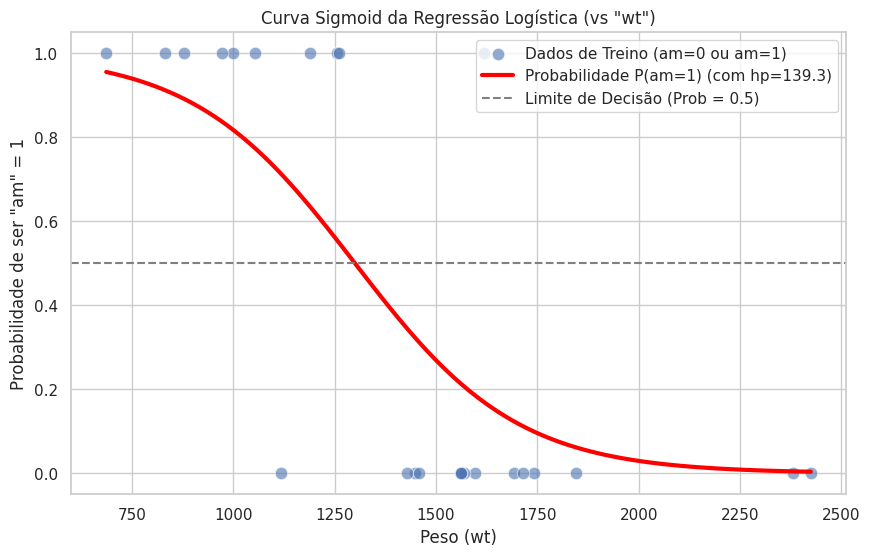

In [ ]:
# vamos visualisar graficamente em 2D
# Manter 'hp' constante na média dos dados de treino
hp_mean = X_logit_train['hp'].mean()

# Gerar um range de valores para 'wt' (para uma curva suave)
wt_range = np.linspace(X_logit_train['wt'].min(), X_logit_train['wt'].max(), 100)

#Criar o DataFrame sintético para predição
X_synthetic = pd.DataFrame({
    'wt': wt_range,
    'hp': hp_mean
})

#Obter as probabilidades (P(am=1))
# predict_proba() retorna [prob_classe_0, prob_classe_1]
y_probs = logit_fit.predict_proba(X_synthetic)[:, 1] # pegando a prob da classe 1, lembrando p(0)= 1-p(1)

# Plotar
plt.figure(figsize=(10, 6))

# Plotar os dados reais (com jitter para ver a densidade)
sns.scatterplot(
    x=X_logit_train['wt'],
    y=y_logit_train,
    alpha=0.6,
    label='Dados de Treino (am=0 ou am=1)',
    s=80
)


# Plotar a curva S
plt.plot(wt_range, y_probs, color='red', linewidth=3, label=f'Probabilidade P(am=1) (com hp={hp_mean:.1f})')

# Linha de decisão (0.5)
plt.axhline(0.5, color='grey', linestyle='--', label='Limite de Decisão (Prob = 0.5)')

plt.title('Curva Sigmoid da Regressão Logística (vs "wt")')
plt.xlabel('Peso (wt)')
plt.ylabel('Probabilidade de ser "am" = 1')
plt.legend()
plt.show()

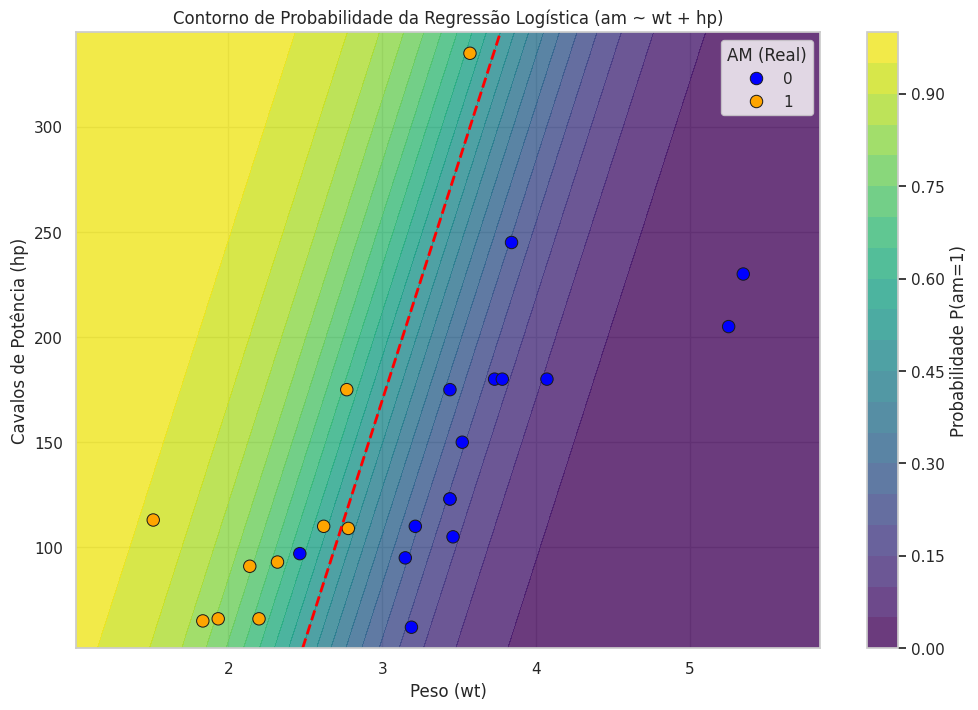

In [ ]:
# em 3D
# (meshgrid)
wt_min, wt_max = X_logit_train['wt'].min() - 0.5, X_logit_train['wt'].max() + 0.5
hp_min, hp_max = X_logit_train['hp'].min() - 10, X_logit_train['hp'].max() + 10
xx_wt, yy_hp = np.meshgrid(np.linspace(wt_min, wt_max, 100),
                            np.linspace(hp_min, hp_max, 100))

# DataFrame da grade
grid_df = pd.DataFrame(np.c_[xx_wt.ravel(), yy_hp.ravel()], columns=['wt', 'hp'])

# Prever PROBABILIDADES para a grade
Z_probs = logit_fit.predict_proba(grid_df)[:, 1] # Probabilidade da classe 1
Z = Z_probs.reshape(xx_wt.shape)

# Plot de Contorno
plt.figure(figsize=(12, 8))
contour = plt.contourf(xx_wt, yy_hp, Z, 20, cmap='viridis', alpha=0.8)
plt.colorbar(contour, label='Probabilidade P(am=1)')

#Plota os pontos de treino
# Usamos 'assign' para adicionar 'am' temporariamente para o plot
sns.scatterplot(
    data=X_logit_train.assign(am=y_logit_train),
    x='wt',
    y='hp',
    hue='am',
    palette={0: 'blue', 1: 'orange'},
    edgecolors='k',
    s=80
)

# Adicionar o contorno da decisão (linha de 0.5)
plt.contour(xx_wt, yy_hp, Z, levels=[0.5], colors='red', linestyles='--', linewidths=2)

plt.title('Contorno de Probabilidade da Regressão Logística (am ~ wt + hp)')
plt.xlabel('Peso (wt)')
plt.ylabel('Cavalos de Potência (hp)')
plt.legend(title='AM (Real)')
plt.show()


## K-Vizinhos mais proximos (KNN)

O KNN Define a classe do novo ponto baseado na distancia dos pontos mais próximos a eles, são escolhidos K pontos mais próximos para definir por votação simples ou seja, quem tem mais ponto da mesma classe proxima define a classificação do novo ponto.

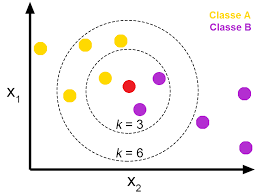


O modelo de [KNN](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) (k-nearest_neighbor), possui uma serie de hiperparametros a serem escolhidos, vamos destacar:

1. neighbors:defini quantos vizinhos próximos vão ser levando em conta no processamento\n",
2. weights: 'uniform'- todos os pontos tem o mesmo peso independente da distancia, 'distance'- peso diferentes para o voto conforme a distancia (weight = 1/distance)
2. metric: Como é calculada a distancia
        


## kNN Classificação - Métricas (Dados de Treino) ##
Acurácia: 0.8800

Matriz de Confusão (Treino):


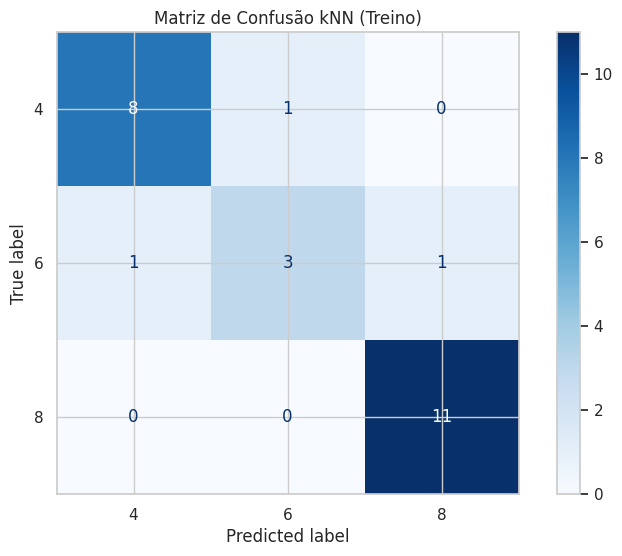

Plotando regiões de decisão para kNN (Classificação)...


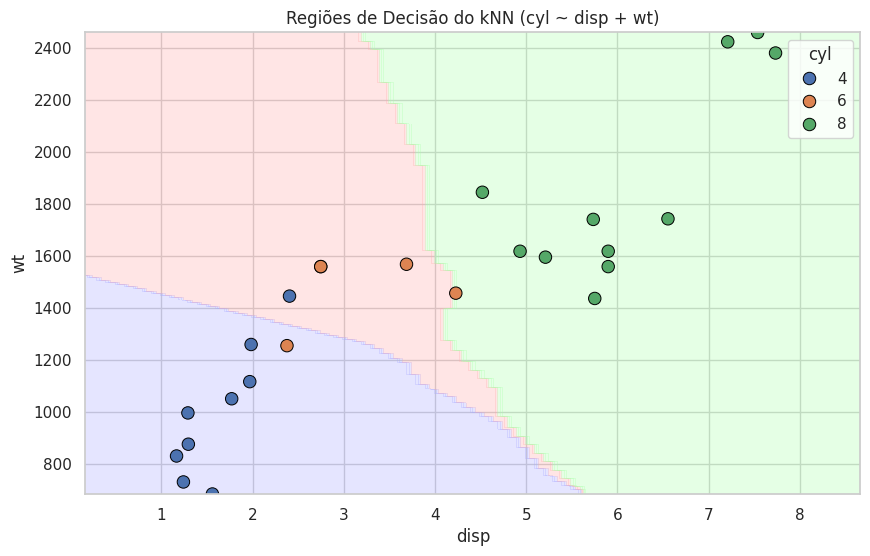


## kNN Classificação - Métricas (Dados de Teste) ##
Acurácia: 0.5714

Matriz de Confusão (Teste):


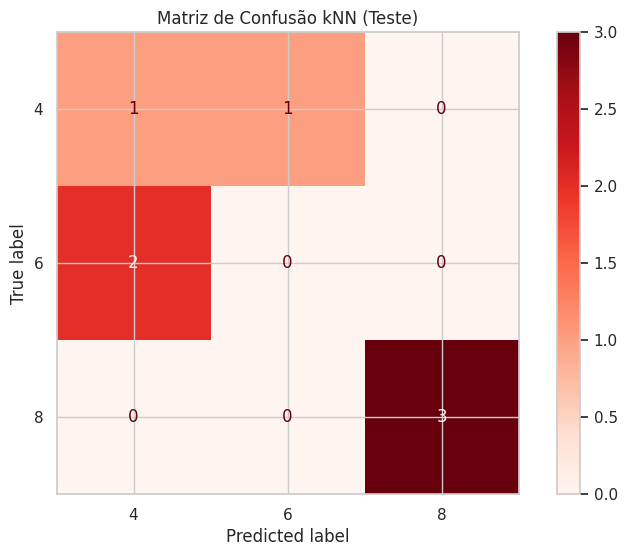

In [ ]:
# Prepara dados
mtcars_knn_c = mtcars.copy()
mtcars_knn_c['cyl'] = mtcars_knn_c['cyl'].astype('category') # Garantir que 'cyl' é categoria
y_knn_c = mtcars_knn_c['cyl']
X_knn_c = mtcars_knn_c[['disp', 'wt']]

# Divisão
X_knn_c_train, X_knn_c_test, y_knn_c_train, y_knn_c_test = train_test_split(
    X_knn_c, y_knn_c, test_size=0.20, stratify=mtcars_knn_c['cyl'], random_state=2025
)

# Escala os dados

preprocessor_knn_c = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['disp', 'wt'])
    ],
    remainder='passthrough'
)

# Modelo (k=3)
knn_c_model = KNeighborsClassifier(n_neighbors=5)

# Workflow
knn_c_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_knn_c),
    ('model', knn_c_model)
])

# Treinamento
knn_c_fit = knn_c_wflow.fit(X_knn_c_train, y_knn_c_train)

# fit
y_knn_c_pred_train = knn_c_fit.predict(X_knn_c_train)

print("\n## kNN Classificação - Métricas (Dados de Treino) ##")
print(f"Acurácia: {accuracy_score(y_knn_c_train, y_knn_c_pred_train):.4f}")
print("\nMatriz de Confusão (Treino):")

cm = confusion_matrix(y_knn_c_train, y_knn_c_pred_train)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn_c_fit.classes_)
disp.plot(cmap='Blues')
plt.title("Matriz de Confusão kNN (Treino)")
plt.show()

#Plota Regiões de Decisão
print("Plotando regiões de decisão para kNN (Classificação)...")
le_cyl = LabelEncoder().fit(y_knn_c_train)
plot_decision_regions(
    X_knn_c_train, y_knn_c_train, knn_c_fit,
    title="Regiões de Decisão do kNN (cyl ~ disp + wt)",
    le=le_cyl
)

# Métricas (no dataset de TESTE)
y_knn_c_pred_test = knn_c_fit.predict(X_knn_c_test)

print("\n## kNN Classificação - Métricas (Dados de Teste) ##")
print(f"Acurácia: {accuracy_score(y_knn_c_test, y_knn_c_pred_test):.4f}")


print("\nMatriz de Confusão (Teste):")
cm_test = confusion_matrix(y_knn_c_test, y_knn_c_pred_test)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=knn_c_fit.classes_)
disp_test.plot(cmap='Reds') # Cor diferente para diferenciar
plt.title("Matriz de Confusão kNN (Teste)")
plt.show()


Podemos usar o KNN como Regressor

In [ ]:

# Objetivo: Prever 'mpg' usando todos os outros preditores

# Preparar dados
y_knn_r = mtcars['mpg']
X_knn_r = mtcars.drop(['mpg','model'], axis=1) # modelo não queremos

# Divisão
X_knn_r_train, X_knn_r_test, y_knn_r_train, y_knn_r_test = train_test_split(
    X_knn_r, y_knn_r, test_size=0.30, random_state=2025
)



# Identificar colunas
# Vamos tratar como categóricas as que têm < 10 valores únicos
categorical_features = [col for col in X_knn_r.columns if X_knn_r[col].nunique() < 10]
numeric_features = [col for col in X_knn_r.columns if col not in categorical_features]

print(f"Variáveis numéricas: {numeric_features}")
print(f"Variáveis categóricas: {categorical_features}")

# Criar transformadores
numeric_transformer = Pipeline(steps=[('scaler', StandardScaler())])
categorical_transformer = Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore'))])

# Combinar no ColumnTransformer
preprocessor_knn_r = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

#  Modelo
knn_r_model = KNeighborsRegressor(n_neighbors=5)

#  Workflow
knn_r_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_knn_r),
    ('model', knn_r_model)
])

#  Treinamento
knn_r_fit = knn_r_wflow.fit(X_knn_r_train, y_knn_r_train)

#  Métricas (Treino)
y_knn_r_pred_train = knn_r_fit.predict(X_knn_r_train)
print("\n## kNN Regressão - Métricas (Dados de Treino) ##")
print(f"RMSE: {np.sqrt(mean_squared_error(y_knn_r_train, y_knn_r_pred_train)):.4f}")
print(f"R²:   {r2_score(y_knn_r_train, y_knn_r_pred_train):.4f}")

# 7. Métricas (Teste)
y_knn_r_pred_test = knn_r_fit.predict(X_knn_r_test)
print("\n## kNN Regressão - Métricas (Dados de Teste) ##")
print(f"RMSE: {np.sqrt(mean_squared_error(y_knn_r_test, y_knn_r_pred_test)):.4f}")
print(f"R²:   {r2_score(y_knn_r_test, y_knn_r_pred_test):.4f}")

Variáveis numéricas: ['disp', 'hp', 'drat', 'wt', 'qsec']
Variáveis categóricas: ['cyl', 'vs', 'am', 'gear', 'carb']

## kNN Regressão - Métricas (Dados de Treino) ##
RMSE: 2.7872
R²:   0.7763

## kNN Regressão - Métricas (Dados de Teste) ##
RMSE: 3.1387
R²:   0.7269


Note: temos um problema de overfitting, como podemos ajustar?

## Suport vector Machine

O objetivo do SVM é separar os conjuntos de dados por meio de um hiperplano, esse hiperplano é defino como um numero menor da dimensão dos dados, no caso de duas dimensões o hiperplano definido pelo SVM sera uma reta, caso 3 dimensões sera definido como um plano e assim sucessivamente. Como podemos observar na figura, o hiperplano (reta) é posicionado com base em maximizar a distancia da margem entre os pontos de suporte (vetores de suporte).

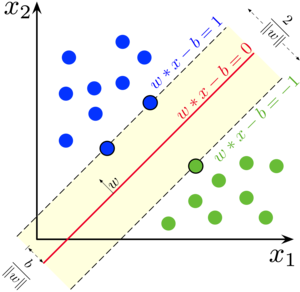

Equação da reta: $w_1x_1 + w_2x_2 - b = 0$

hiperplano generico: $w_ix_i - b = 0$

Objetivo: Maximizar a distância entre as margens: $d = {2}/{||w||}$

"Sendo assim tenho que minimizar o ||w||

E podemos permitir alguns erros, para tornar as margem mais flexível em busca do melhor ajuste, para isso, podemos acrescentar uma possibilidade de erro ponderada por um coeficiente \"C\":

para o mínimo de: ${||w||} + C\sum{\\\\erro_i}$

Quanto maior o C menor é a tolerância da margem com os erros.

E quando não podemos separa com um plano na mesma dimensão, podemos utilizar o truque do kernel, que simula os dados em uma maior dimensão para poder encontrar o hiperplano como ilustrado na figura.

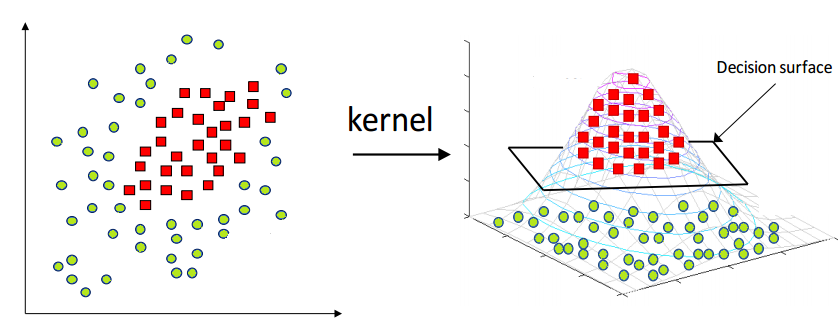\n",

Temos 3 tipos de Kernel a utilizar para o SVM.

1.   [Linear](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html#sklearn.svm.LinearSVC)> para quando você reconhecer uma separação linear

2.   [Polinomial](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC)> quando a separação for mais complexa

3. [Radial basis function](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC)> quando desconhece a relação de agrupamento



## SVM Linear (am) - Métricas (Dados de Treino) ##
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        15
           1       0.90      0.90      0.90        10

    accuracy                           0.92        25
   macro avg       0.92      0.92      0.92        25
weighted avg       0.92      0.92      0.92        25

Plotando regiões de decisão para SVM Linear (am ~ wt + hp)...


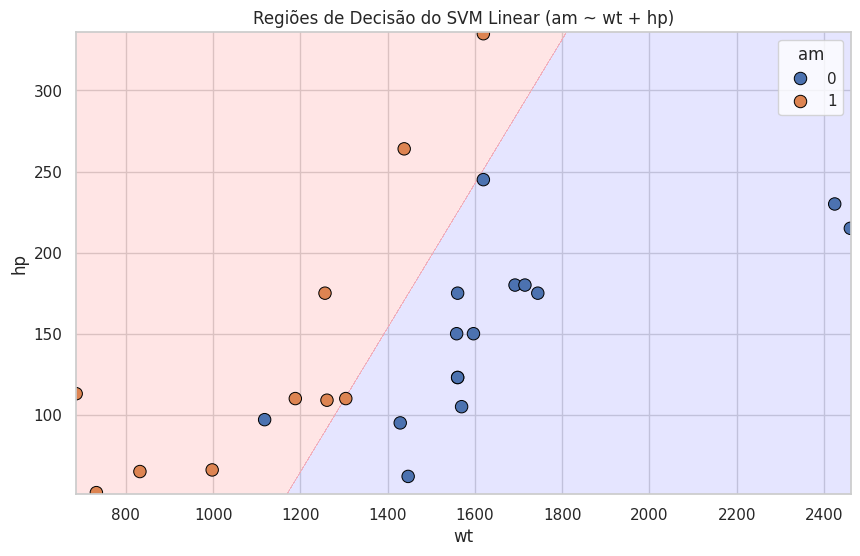

In [ ]:
# Preparar dados para 'am'
mtcars['am'] = mtcars['am'].astype('category')
y_svm_l = mtcars['am']
X_svm_l = mtcars[['wt', 'hp']]

#  Divisão
X_svm_l_train, X_svm_l_test, y_svm_l_train, y_svm_l_test = train_test_split(
    X_svm_l, y_svm_l, test_size=0.20, stratify=mtcars['am'], random_state=2024
)

# (scalonamento)
preprocessor_svm_l = ColumnTransformer(
    transformers=[('num', StandardScaler(), ['wt', 'hp'])],
    remainder='passthrough'
)

#  Modelo (kernel='linear')
svm_l_model = SVC(kernel='linear')

# Workflow
svm_l_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_svm_l),
    ('model', svm_l_model)
])

# Treinamento
svm_l_fit = svm_l_wflow.fit(X_svm_l_train, y_svm_l_train)

# Métricas (Treino)
y_svm_l_pred_train = svm_l_fit.predict(X_svm_l_train)
print("\n## SVM Linear (am) - Métricas (Dados de Treino) ##")
print(classification_report(y_svm_l_train, y_svm_l_pred_train))

#  Plot
print("Plotando regiões de decisão para SVM Linear (am ~ wt + hp)...")
le_am = LabelEncoder().fit(y_svm_l_train)
plot_decision_regions(
    X_svm_l_train, y_svm_l_train, svm_l_fit,
    title="Regiões de Decisão do SVM Linear (am ~ wt + hp)",
    le=le_am
)



--- SEÇÃO 6: SVM (CLASSIFICAÇÃO) - POLINOMIAL ---

## SVM Polinomial (am) - Métricas (Dados de Treino) ##
              precision    recall  f1-score   support

           0       0.79      1.00      0.88        15
           1       1.00      0.60      0.75        10

    accuracy                           0.84        25
   macro avg       0.89      0.80      0.82        25
weighted avg       0.87      0.84      0.83        25

Plotando regiões de decisão para SVM Polinomial (am ~ wt + hp)...


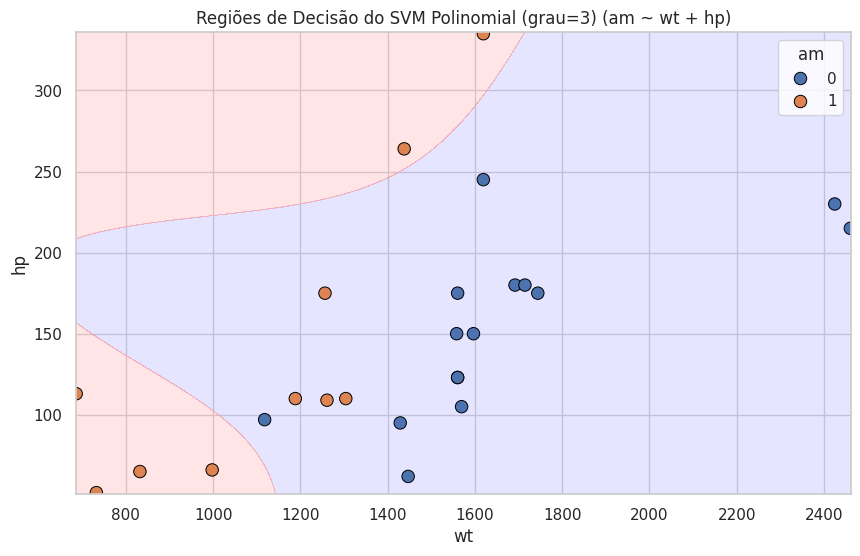

In [ ]:
# POLINOMIAL

# Reutilizando os mesmos dados da Seção anterior

# preprocessamento igual
preprocessor_svm_p = preprocessor_svm_l

#Modelo (kernel='poly', degree=3)
svm_p_model = SVC(kernel='poly', degree=3)

# Workflow
svm_p_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_svm_p),
    ('model', svm_p_model)
])

# Treinamento
svm_p_fit = svm_p_wflow.fit(X_svm_l_train, y_svm_l_train)

# Métricas (Treino)
y_svm_p_pred_train = svm_p_fit.predict(X_svm_l_train)
print("\n## SVM Polinomial (am) - Métricas (Dados de Treino) ##")
print(classification_report(y_svm_l_train, y_svm_p_pred_train))

#  Plot
print("Plotando regiões de decisão para SVM Polinomial (am ~ wt + hp)...")
plot_decision_regions(
    X_svm_l_train, y_svm_l_train, svm_p_fit,
    title="Regiões de Decisão do SVM Polinomial (grau=3) (am ~ wt + hp)",
    le=le_am # Reutilizando o LabelEncoder da seção anterior
)

SVM tem sua versão para regressão(SVR - Support Vector Regression)


## SVR - Métricas (Dados de Teste) ##
RMSE: 1.1434
R²:   0.7171
Plotando superfície de predição do SVR...


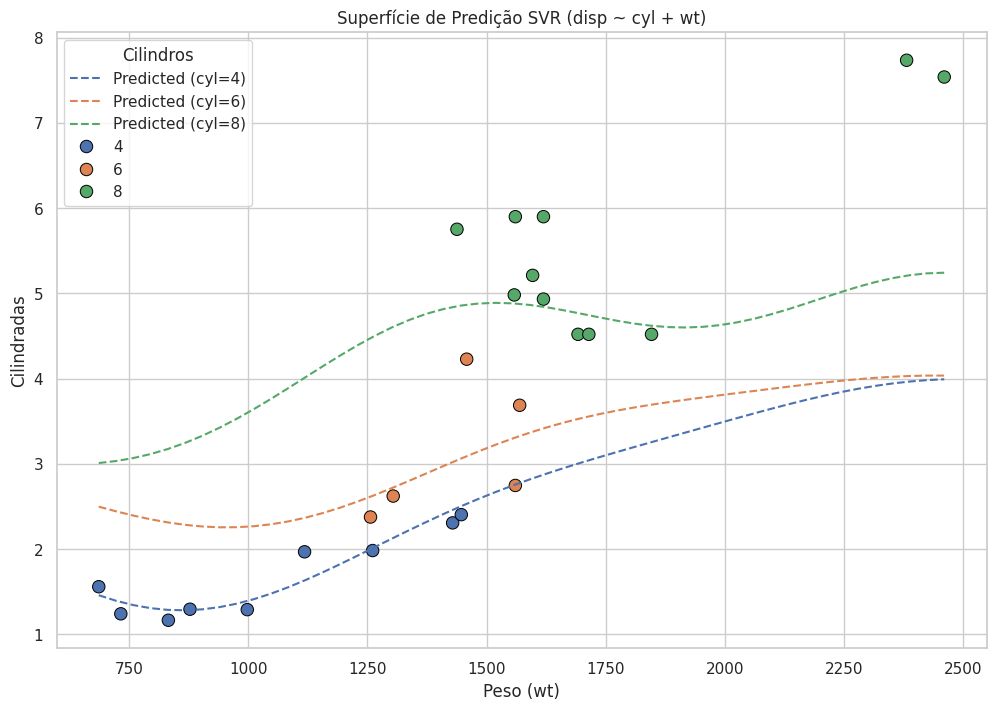

In [ ]:
# Seleção de variaveis
y_svr = mtcars['disp']
X_svr = mtcars[['cyl', 'wt']]

# Divisão de dados
X_svr_train, X_svr_test, y_svr_train, y_svr_test = train_test_split(
    X_svr, y_svr, test_size=0.20, stratify=mtcars['cyl'], random_state=2024
)

# (pré-processamento)

# Vamos usar StandardScaler.
preprocessor_lm = ColumnTransformer(
    transformers=[
        # ('nome', transformador, colunas)
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['cyl']),
        ('num', StandardScaler(), ['wt'])
    ],
    remainder='drop' # Ignora outras colunas se houver
)
# 3. Modelo (SVR - Support Vector Regression)
svr_model = SVR(kernel='rbf') # RBF (Radial Basis Function) é um bom padrão

# 4. Workflow
svr_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_lm), # Corrigido de preprocessor_svr para preprocessor_lm
    ('model', svr_model)
])

# 5. Treinamento
svr_fit = svr_wflow.fit(X_svr_train, y_svr_train)

# 6. Métricas (Teste)
y_svr_pred_test = svr_fit.predict(X_svr_test)
print("\n## SVR - Métricas (Dados de Teste) ##")
print(f"RMSE: {np.sqrt(mean_squared_error(y_svr_test, y_svr_pred_test)):.4f}")
print(f"R²:   {r2_score(y_svr_test, y_svr_pred_test):.4f}")

# Plot de Contorno (Superfície de Predição) - Adaptação para features 'cyl' e 'wt'
print("Plotando superfície de predição do SVR...")

# Define ranges for 'wt'
wt_range_for_plot = np.linspace(X_svr_train['wt'].min(), X_svr_train['wt'].max(), 50)
cyl_values = X_svr_train['cyl'].unique()
cyl_values.sort()

plt.figure(figsize=(12, 8))
colors = sns.color_palette("deep", n_colors=len(cyl_values))

for i, cyl_val in enumerate(cyl_values):
    # temos que criar uma previsão para cada cilindro para visualisar
    grid_data_cyl = pd.DataFrame({
        'cyl': np.full_like(wt_range_for_plot, cyl_val, dtype=int),
        'wt': wt_range_for_plot
    })

    # previsão apra cada cilindro
    predicted_disp = svr_fit.predict(grid_data_cyl)

    # Plota a previsão
    plt.plot(wt_range_for_plot, predicted_disp, color=colors[i], linestyle='--', label=f'Predicted (cyl={cyl_val})')

# Plot os pontos originais
sns.scatterplot(
    x=X_svr_train['wt'],
    y=y_svr_train,
    hue=X_svr_train['cyl'],
    palette=sns.color_palette("deep", n_colors=len(cyl_values)),
    s=80,
    edgecolor="black"
)

plt.title("Superfície de Predição SVR (disp ~ cyl + wt)")
plt.xlabel("Peso (wt)")
plt.ylabel("Cilindradas")
plt.legend(title='Cilindros')
plt.show()

Atividade, dado o conjunto abaixo, relação não linear como podemos resolver.

Dados em espiral gerados. Plotando...


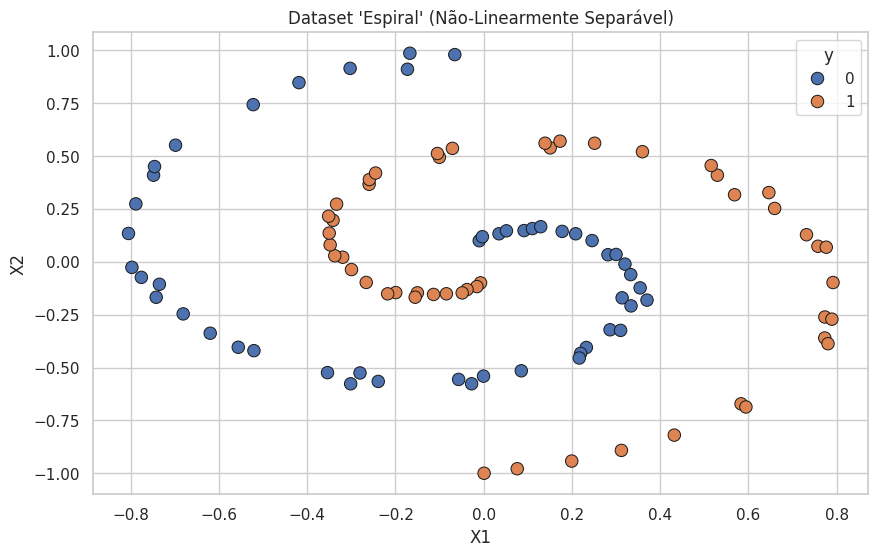

In [ ]:


# Gerar os dados aspirais
spiral_data = make_spirals(n_points=100, noise=0.1, n_turns=1)

X_spiral = spiral_data[['X1', 'X2']]
y_spiral = spiral_data['y']

print("Dados em espiral gerados. Plotando...")
sns.scatterplot(data=spiral_data, x='X1', y='X2', hue='y', s=80, edgecolor='k')
plt.title("Dataset 'Espiral' (Não-Linearmente Separável)")
plt.show()




Treinando SVM Linear na espiral...
Treinando SVM RBF (Radial) na espiral...
Treinando SVM Polinomial (grau 5) na espiral...


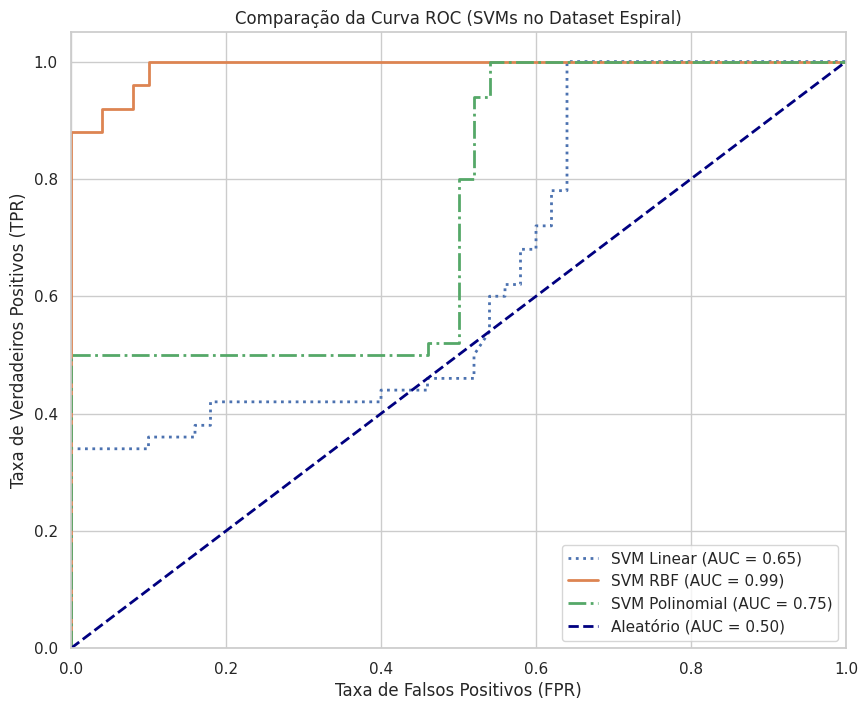

Plotando falha do SVM Linear...


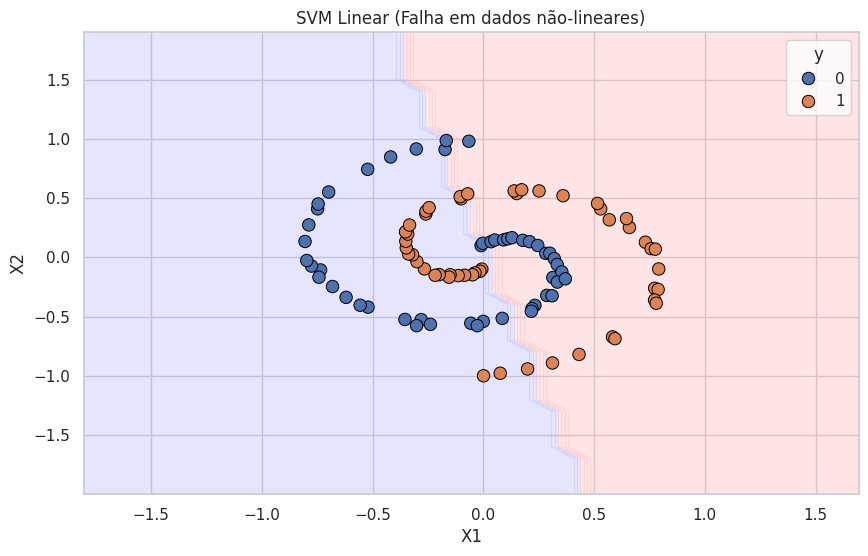

Plotando sucesso do SVM RBF...


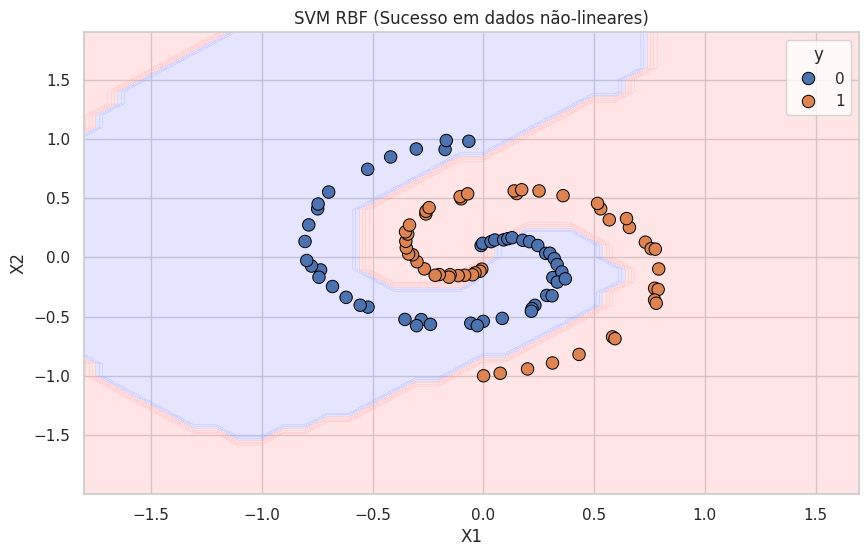

Plotando SVM Polinomial (grau 5)...


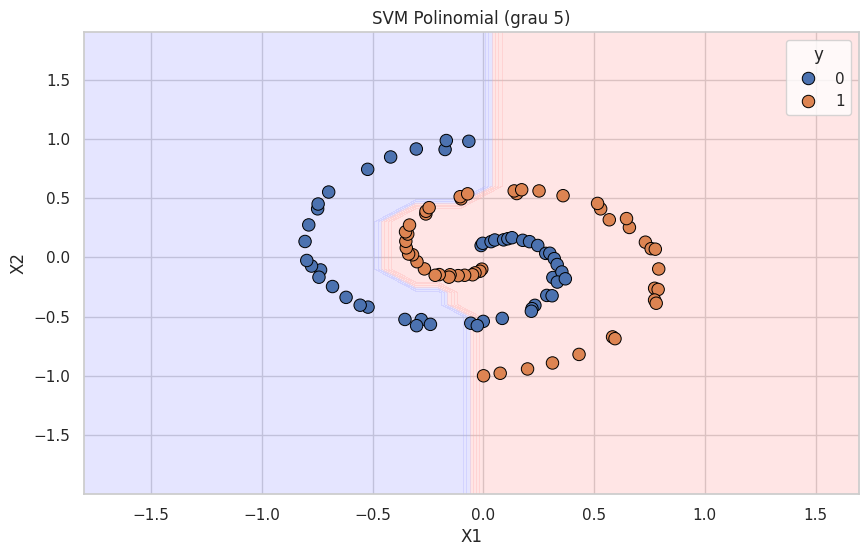

In [ ]:
# soluçãoes possiveis
#  Pré-processador (Apenas normalização)
preprocessor_spiral = ColumnTransformer(
    transformers=[('num', StandardScaler(), ['X1', 'X2'])],
    remainder='passthrough'
)

# Modelos a comparar, probability=True para usar a ROC
svm_linear_spiral = SVC(kernel='linear',probability=True)
svm_rbf_spiral = SVC(kernel='rbf', C=1.0, gamma='auto',probability=True) # RBF (Radial)
svm_poly_spiral = SVC(kernel='poly', degree=5,probability=True) # Polinomial

# Pipeline e Fit - Linear
print("Treinando SVM Linear na espiral...")
svm_lin_spiral_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_spiral),
    ('model', svm_linear_spiral)
])
svm_lin_spiral_fit = svm_lin_spiral_wflow.fit(X_spiral, y_spiral)

#  Pipeline e Fit - RBF
print("Treinando SVM RBF (Radial) na espiral...")
svm_rbf_spiral_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_spiral),
    ('model', svm_rbf_spiral)
])
svm_rbf_spiral_fit = svm_rbf_spiral_wflow.fit(X_spiral, y_spiral)

# Pipeline e Fit - Polinomial
print("Treinando SVM Polinomial (grau 5) na espiral...")
svm_poly_spiral_wflow = Pipeline(steps=[
    ('preprocessor', preprocessor_spiral),
    ('model', svm_poly_spiral)
])
svm_poly_spiral_fit = svm_poly_spiral_wflow.fit(X_spiral, y_spiral)


# Plotar Regiões de Decisão
le_spiral = LabelEncoder().fit(y_spiral)


# Obter as probabilidades (scores) para a classe positiva (1)
# Avaliando nos próprios dados de treino (para fins de demonstração da separabilidade)
y_score_linear = svm_lin_spiral_fit.predict_proba(X_spiral)[:, 1]
y_score_rbf = svm_rbf_spiral_fit.predict_proba(X_spiral)[:, 1]
y_score_poly = svm_poly_spiral_fit.predict_proba(X_spiral)[:, 1]

# Converter y_spiral para numérico (0 e 1)
y_spiral_numeric = le_spiral.transform(y_spiral)

# Calcular FPR, TPR e AUC para cada modelo
fpr_lin, tpr_lin, _ = roc_curve(y_spiral_numeric, y_score_linear)
auc_lin = auc(fpr_lin, tpr_lin)

fpr_rbf, tpr_rbf, _ = roc_curve(y_spiral_numeric, y_score_rbf)
auc_rbf = auc(fpr_rbf, tpr_rbf)

fpr_poly, tpr_poly, _ = roc_curve(y_spiral_numeric, y_score_poly)
auc_poly = auc(fpr_poly, tpr_poly)

# Plotar as 3 curvas ROC juntas
plt.figure(figsize=(10, 8))
plt.plot(fpr_lin, tpr_lin, lw=2, linestyle=':',
         label=f'SVM Linear (AUC = {auc_lin:.2f})') # Linha pontilhada para o modelo ruim
plt.plot(fpr_rbf, tpr_rbf, lw=2, linestyle='-',
         label=f'SVM RBF (AUC = {auc_rbf:.2f})') # Linha sólida para o modelo bom
plt.plot(fpr_poly, tpr_poly, lw=2, linestyle='-.',
         label=f'SVM Polinomial (AUC = {auc_poly:.2f})') # Linha traço-ponto

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aleatório (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Comparação da Curva ROC (SVMs no Dataset Espiral)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


# Plotar Regiões de Decisão
# le_spiral = LabelEncoder().fit(y_spiral) # <-- Movido para cima

print("Plotando falha do SVM Linear...")
plot_decision_regions(
    X_spiral, y_spiral, svm_lin_spiral_fit,
    title="SVM Linear (Falha em dados não-lineares)",
    le=le_spiral
)

print("Plotando sucesso do SVM RBF...")
plot_decision_regions(
    X_spiral, y_spiral, svm_rbf_spiral_fit,
    title="SVM RBF (Sucesso em dados não-lineares)",
    le=le_spiral
)

print("Plotando SVM Polinomial (grau 5)...")
plot_decision_regions(
    X_spiral, y_spiral, svm_poly_spiral_fit,
    title="SVM Polinomial (grau 5)",
    le=le_spiral
)

Para entender [ROC-AUC](https://https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc?hl=pt-br)